# TOGAXSI：alpha–p 径迹、反应顶点和运动学重建

**功能**：读取当前目录 `alphap.root/SimulatedTree`，用 SSD 条带重建出射 alpha 径迹、反应顶点及反冲质子方向，以一行三列绘制顶点 XYZ 残差，并绘制质子 theta 的“重建值 − 真值”分布，以及一行两列的质子/alpha 顶点总动能–theta 图。

**方法**：uproot / awkward 保留逐事件 hit；NumPy float64 复现 `UseClusterTrack/ReconstrucionTOGAXSI_HitsLocal.C` 及 `TOGAXSIReconstrution.cc` 的拟合和解析求交。`KinLoss.C` 仅负责外部 C++ 能损和理论曲线，Python 负责径迹、顶点与绘图；不会直接运行原重建宏。

**注意事项**：从上到下逐块执行。当前输入没有 VirtualBDC，按约定采用 `ReactionConditions` 的束流方向真值定义 theta；顶点和出射径迹不使用位置或出射方向真值。几何取输入 ROOT 内嵌的 DetectorConfiguration。长度 mm、角度 deg、绘图能量为总动能 MeV。失败保留原事件并设为具名 `INVALID=-999.0`，统计只使用相应成功标志。

只在本 Notebook 所在目录下新建输出；外部源码和输入 ROOT 只读。此文件交付时未运行重建、C++ 或绘图，不代表已验证 Python/C++ 数值一致。


## 1. 导入与集中配置

在当前文件夹运行，Python 环境需要 uproot、awkward、NumPy、Matplotlib；能损与理论曲线还需要命令行 ROOT。


In [19]:
from pathlib import Path
from datetime import datetime
import json
import re
import shutil
import subprocess

import awkward as ak
import numpy as np
import uproot
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

WORK_DIR = Path.cwd().resolve()
INPUT = WORK_DIR / "alphap.root"
HELPER = WORK_DIR / "KinLoss.C"
TREE_NAME = "SimulatedTree"
INVALID = -999.0
CHUNK_SIZE = 10000
MAX_ENTRIES = None  # None：全部事件；调试时可改成较小的整数。
OUT_DIR = WORK_DIR / datetime.now().strftime("output/%Y%m%d/%H%M%S")
GROUPS = ("LU", "LD", "RU", "RD", "U", "D")
GAGG_GROUPS = ("LU", "LD", "RU", "RD", "UP", "DOWN")
REFERENCE = Path("/Users/yemingxin/nptool/Projects/myTOGAXSI_ppalpha/Reconstruction")
REFERENCE_MACRO = REFERENCE / "Scattering/UseClusterTrack/ReconstrucionTOGAXSI_HitsLocal.C"
print("输入：", INPUT)
print("输出：", OUT_DIR)


输入： /Users/yemingxin/ROOT_Exercise/MachineLearning/ReadROOT/ReadStruct/alphap.root
输出： /Users/yemingxin/ROOT_Exercise/MachineLearning/ReadROOT/ReadStruct/output/20261026/181132


## 2. 输入元信息与几何配置

本块只读取输入文件中的配置与条目数。采用随 ROOT 保存的配置，避免外部 detector 文件后续改变导致坐标系不一致。


In [20]:
with uproot.open(INPUT) as root_file:
    tree = root_file[TREE_NAME]
    total_entries = tree.num_entries
    detector_text = "\n".join(str(x) for x in root_file["DetectorConfiguration"].member("fLines"))
    reaction_text = "\n".join(str(x) for x in root_file["EventGenerator"].member("fLines"))
    top_branches = tree.keys(recursive=False)

n_entries = total_entries if MAX_ENTRIES is None else min(total_entries, MAX_ENTRIES)
print("总事件数：", total_entries, "；本次读取：", n_entries)
print("顶层分支：", top_branches)
print("束流方向来源：ReactionConditions（模拟真值；本输入没有 VirtualBDC）")


总事件数： 300000 ；本次读取： 300000
顶层分支： ['EventID', 'ReactionSkipped', 'InteractionCoordinates', 'RecoilSSD', 'RecoilGAGG', 'RecoilGAGGPMT', 'ClusterSSD', 'ClusterGAGG', 'ClusterGAGGPMT', 'ReactionChannel', 'InitialConditions', 'ReactionConditions', 'TrackInfo', 'Run']
束流方向来源：ReactionConditions（模拟真值；本输入没有 VirtualBDC）


In [21]:
def config_blocks(text, token):
    """读取当前配置中启用的块；% 后为注释，空行或下一块结束当前块。"""
    blocks = []
    current = None
    for raw_line in text.splitlines():
        line = raw_line.split("%", 1)[0].strip()
        if not line:
            if current:
                blocks.append(current)
            current = None
        elif "=" not in line:
            if current:
                blocks.append(current)
            current = {} if line == token else None
        elif current is not None:
            key, value = line.split("=", 1)
            current[key.strip().upper()] = value.strip()
    if current:
        blocks.append(current)
    return blocks


def value_in_unit(block, key, unit):
    parts = block[key].split()
    if len(parts) != 2 or parts[1] != unit:
        raise ValueError(f"{key} 应使用 {unit}：{block[key]}")
    return float(parts[0])


def build_geometry(text):
    """对应 BuildRecoilGroupGeometry / SetRecoilGroupAxis。"""
    geometry = {}
    type_names = {"LU": "LU", "LD": "LD", "RU": "RU", "RD": "RD", "UP": "U", "DOWN": "D"}
    for block in config_blocks(text, "RecoilSSD"):
        match = re.fullmatch(r"RecoilSi(LU|LD|RU|RD|UP|DOWN)X1", block["TYPE"])
        if match is None:
            continue
        parts = block["POS"].split()
        if len(parts) != 4 or parts[-1] != "mm":
            raise ValueError("RecoilSSD POS 必须是三个坐标和 mm")
        origin = np.asarray(parts[:3], dtype=np.float64)
        local_x = np.array([0.0, 0.0, -1.0])
        local_z = np.array([origin[0], origin[1], 0.0])
        local_z /= np.linalg.norm(local_z)
        local_y = np.cross(local_z, local_x)
        local_y /= np.linalg.norm(local_y)
        rotation = np.column_stack((local_x, local_y, local_z))
        geometry[type_names[match[1]]] = (origin, rotation)
    return geometry


geometry = build_geometry(detector_text)
target = config_blocks(detector_text, "Target")[0]
TARGET_THICKNESS = value_in_unit(target, "THICKNESS", "mm")
TARGET_RADIUS = value_in_unit(target, "RADIUS", "mm")
# KinLoss 的几何与 HitsLocal 一致：中心原点、无倾斜的圆柱 LH2 靶。
if target["MATERIAL"] != "LH2" or any(
    value_in_unit(target, key, unit) != 0.0
    for key, unit in (("X", "mm"), ("Y", "mm"), ("Z", "mm"), ("ANGLE", "deg"))
):
    raise ValueError("当前能损接口仅适用于中心原点、ANGLE=0 的 LH2 靶")
beam = config_blocks(reaction_text, "Beam")[0]
if beam["PARTICLE"] != "4He":
    raise ValueError("当前 Notebook 针对 4He+p 弹性散射")
BEAM_ENERGY_PER_U = value_in_unit(beam, "ENERGY", "MeV") / 4.0
print("启用 Recoil 组：", list(geometry))
print("LH2 厚度/半径 (mm)：", TARGET_THICKNESS, TARGET_RADIUS)
print("参考曲线束流能量 (MeV/u)：", BEAM_ENERGY_PER_U)


启用 Recoil 组： ['LD', 'LU', 'RU', 'RD']
LH2 厚度/半径 (mm)： 150.0 15.5
参考曲线束流能量 (MeV/u)： 200.0


## 3. Python 径迹拟合与坐标变换函数

alpha 分别拟合 `x=a·z+b`、`y=c·z+d`。拟合矩阵和失败阈值对应当前 `LeastSquares.cc`，包括三点及以上拟合时的 `chi2 <= 1e-10` 限制。Recoil 局域旋转矩阵的列是局域轴在世界坐标中的方向。


### 3.1 alpha 四层条带的投影拟合


In [22]:
def least_squares(z, coordinate):
    z = np.asarray(z, dtype=np.float64)
    coordinate = np.asarray(coordinate, dtype=np.float64)
    n = len(z)
    if n < 2 or len(coordinate) != n or not np.all(np.isfinite([z, coordinate])):
        return None
    sum_z, sum_q = z.sum(), coordinate.sum()
    sum_zz, sum_zq = np.dot(z, z), np.dot(z, coordinate)
    matrix = np.array([[sum_zz, sum_z], [sum_z, float(n)]])
    if abs(sum_zz * n - sum_z * sum_z) < 1.0e-5:
        return None
    try:
        slope, intercept = np.linalg.solve(matrix, [sum_zq, sum_q])
    except np.linalg.LinAlgError:
        return None
    chi2 = np.sum((coordinate - slope * z - intercept) ** 2)
    if n > 2 and chi2 <= 1.0e-10:
        return None
    return slope, intercept


def build_cluster_track(hits, side):
    selected = [h for h in hits if h["ClusterSSDGroup"] == side]
    layers = {}
    for hit in selected:
        xy, z = hit["StripXYPositionWorld"], hit["StripZPositionWorld"]
        if not np.all(np.isfinite([xy, z])) or min(xy, z) <= -900.0:
            return None
        layers.setdefault(hit["ClusterSSDType"], []).append(hit)
    if any(len(layers.get(layer, [])) != 1 for layer in ("X1", "X2", "Y1", "Y2")):
        return None
    x_hits = [h for h in selected if h["ClusterSSDType"] in ("X1", "X2")]
    y_hits = [h for h in selected if h["ClusterSSDType"] in ("Y1", "Y2")]
    fit_x = least_squares([h["StripZPositionWorld"] for h in x_hits],
                          [h["StripXYPositionWorld"] for h in x_hits])
    fit_y = least_squares([h["StripZPositionWorld"] for h in y_hits],
                          [h["StripXYPositionWorld"] for h in y_hits])
    if fit_x is None or fit_y is None:
        return None
    a, b = fit_x
    c, d = fit_y
    return np.array([a, c, 1.0]), np.array([b, d, 0.0])


### 3.2 Recoil 选组、坐标变换和解析顶点


In [23]:
def find_recoil_group(hits):
    for group in GROUPS:
        layers = {h["RecoilSSDType"] for h in hits if h["RecoilSSDGroup"] == group}
        if {"X1", "X2"}.issubset(layers):
            return group
    return None


def build_vertex(cluster_track, recoil_hits, group):
    """先拟合质子 X-Z 投影，再在同一局域系解析求交。"""
    x_hits = [h for h in recoil_hits if h["RecoilSSDGroup"] == group
              and h["RecoilSSDType"] in ("X1", "X2")]
    fit = least_squares([h["StripZPositionLocus"] for h in x_hits],
                        [h["StripXYPositionLocus"] for h in x_hits])
    if fit is None:
        return None
    e, f = fit
    origin, rotation = geometry[group]
    direction, point = cluster_track
    local_direction = rotation.T @ direction
    local_point = rotation.T @ (point - origin)
    if abs(local_direction[2]) < 1.0e-9:
        return None
    a, c = local_direction[:2] / local_direction[2]
    b, d = local_point[:2] - np.array([a, c]) * local_point[2]
    if abs(a - e) < 1.0e-9:
        return None
    z0 = (f - b) / (a - e)
    local_vertex = np.array([(a*f - b*e)/(a-e), c*z0+d, z0])
    world_vertex = origin + rotation @ local_vertex
    if not np.all(np.isfinite(world_vertex)):
        return None
    return local_vertex, world_vertex


### 3.3 顶点约束的质子方向及相对束流角


In [24]:
def build_recoil_direction(hits, group, local_vertex):
    """对应 GetFirstRecoilLocusHits：每层只取首个 hit；X2 检查有效性。"""
    first = {}
    for hit in hits:
        if hit["RecoilSSDGroup"] == group:
            first.setdefault(hit["RecoilSSDType"], hit)
    if any(layer not in first for layer in ("X1", "X2", "Y1")):
        return None
    for layer in ("X1", "X2", "Y1"):
        values = [first[layer]["StripXYPositionLocus"], first[layer]["StripZPositionLocus"]]
        if not np.all(np.isfinite(values)) or min(values) <= -900.0:
            return None
    x1, y1 = first["X1"], first["Y1"]
    dz_x = x1["StripZPositionLocus"] - local_vertex[2]
    dz_y = y1["StripZPositionLocus"] - local_vertex[2]
    if abs(dz_x) < 1.0e-9 or abs(dz_y) < 1.0e-9:
        return None
    direction = np.array([(x1["StripXYPositionLocus"] - local_vertex[0]) / dz_x,
                          (y1["StripXYPositionLocus"] - local_vertex[1]) / dz_y, 1.0])
    return geometry[group][1] @ direction


def theta_deg(direction, beam_direction):
    denominator = np.linalg.norm(direction) * np.linalg.norm(beam_direction)
    if not np.isfinite(denominator) or denominator <= 0.0:
        return INVALID
    cosine = np.clip(np.dot(direction, beam_direction) / denominator, -1.0, 1.0)
    return float(np.degrees(np.arccos(cosine)))


## 4. 分支读取、沉积能量求和与真值接口

径迹只读 `StripXYPositionWorld/Locus`、`StripZPositionWorld/Locus`，不读 SSD 的 `InteractionPositionWorld`。沿用 HitsLocal 的组内求和，不追加 TrackID、粒子名、GAGG 击中或穿透切选；因此 E–theta 图沿用原宏的停阻假设，穿透事件可能落在理论曲线下方。


In [25]:
HIT_FIELDS = {
    "ClusterSSD": ("ClusterSSDGroup", "ClusterSSDType", "StripXYPositionWorld", "StripZPositionWorld", "StripEnergy"),
    "RecoilSSD": ("RecoilSSDGroup", "RecoilSSDType", "StripXYPositionLocus", "StripZPositionLocus", "StripEnergy"),
    "ClusterGAGG": ("ClusterGAGGType", "Energy"),
    "RecoilGAGG": ("RecoilGAGGType", "Energy"),
}
RC_FIELDS = ("fRC_Vertex_Position_X", "fRC_Vertex_Position_Y", "fRC_Vertex_Position_Z",
             "fRC_Beam_Emittance_Theta", "fRC_Beam_Emittance_Phi", "fRC_Particle_Name",
             "fRC_Theta", "fRC_Kinetic_Energy", "fReactionOccurred")


def read_chunk(tree, start, stop):
    hit_tables = {}
    for detector, fields in HIT_FIELDS.items():
        name = f"f{detector}Hits"
        branch = tree[f"{detector}/{name}"]
        arrays = {field: branch[f"{name}.{field}"].array(
            entry_start=start, entry_stop=stop, library="ak") for field in fields}
        hit_tables[detector] = ak.to_list(ak.zip(arrays))
    truth = {field: ak.to_list(tree[f"ReactionConditions/{field}"].array(
        entry_start=start, entry_stop=stop, library="ak")) for field in RC_FIELDS}
    ids = tree["EventID"].array(entry_start=start, entry_stop=stop, library="np")
    return ids, hit_tables, truth


def sum_ssd_energy(hits, group_key, group, type_key, layers):
    energies = [sum(h["StripEnergy"] for h in hits
                    if h[group_key] == group and h[type_key] == layer) for layer in layers]
    if any(not np.isfinite(e) or e <= 0.0 for e in energies):
        return INVALID
    return float(sum(energies))


def detector_energies(cluster, recoil, cluster_gagg, recoil_gagg, side, group):
    alpha_ssd = sum_ssd_energy(cluster, "ClusterSSDGroup", side, "ClusterSSDType", ("X1", "X2", "Y1", "Y2"))
    proton_ssd = sum_ssd_energy(recoil, "RecoilSSDGroup", group, "RecoilSSDType", ("X1", "X2", "Y1"))
    alpha_energy = proton_energy = INVALID
    if alpha_ssd > 0.0:
        alpha_types = {"ClusterGAGG", "DeltaEGAGG" + side}
        alpha_energy = alpha_ssd + sum(h["Energy"] for h in cluster_gagg if h["ClusterGAGGType"] in alpha_types)
    if proton_ssd > 0.0:
        gagg_group = GAGG_GROUPS[GROUPS.index(group)]
        proton_energy = proton_ssd + sum(h["Energy"] for h in recoil_gagg if h["RecoilGAGGType"] == gagg_group)
    return alpha_energy, proton_energy


def beam_direction_from_truth(truth, index):
    theta = np.radians(truth["fRC_Beam_Emittance_Theta"][index])
    phi = np.radians(truth["fRC_Beam_Emittance_Phi"][index])
    # 与 TReactionConditions::GetBeamDirection 相同，两个输入角原本为 deg。
    return np.array([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)])


## 5. 逐事件重建：alpha → 反应顶点 → 质子方向

本块执行 Python 重建。全部输入事件均保留，`Entry` 和 `EventID` 供后续对照。`VertexOK` 不要求 Recoil Y1，`RecoilTrackOK` 才要求 X1/X2/Y1；XYZ 残差使用顶点成功样本，质子 theta 残差使用质子径迹成功且有对应真值的样本。

原宏把质子固定为粒子 0、alpha 固定为粒子 1。本 Notebook 核对名称后使用相同顺序；真值只用于残差、存档和已明确允许的束流方向。


In [26]:
result = {"Entry": np.arange(n_entries, dtype=np.int64),
          "EventID": np.zeros(n_entries, dtype=np.uint64),
          "RecoilGroup": np.full(n_entries, -1, dtype=np.int32),
          "ClusterSide": np.full(n_entries, -1, dtype=np.int32)}
for flag in ("ClusterTrackOK", "VertexOK", "RecoilTrackOK", "TruthOK", "BeamOK", "AlphaEnergyOK", "ProtonEnergyOK"):
    result[flag] = np.zeros(n_entries, dtype=bool)
for vector in ("VertexWorld", "VertexLocus", "TrueVertex", "VertexDelta", "ClusterDirection", "ClusterPoint", "RecoilDirection", "BeamDirection"):
    result[vector] = np.full((n_entries, 3), INVALID, dtype=np.float64)
for scalar in ("AlphaTheta", "ProtonTheta", "TrueAlphaTheta", "TrueProtonTheta", "ProtonThetaDiff",
               "AlphaDetectorE", "ProtonDetectorE", "AlphaEnergy", "ProtonEnergy", "TrueAlphaE", "TrueProtonE",
               "AlphaPath", "ProtonPath"):
    result[scalar] = np.full(n_entries, INVALID, dtype=np.float64)


In [27]:
with uproot.open(INPUT) as root_file:
    tree = root_file[TREE_NAME]
    for start in range(0, n_entries, CHUNK_SIZE):
        stop = min(start + CHUNK_SIZE, n_entries)
        ids, hit_tables, truth = read_chunk(tree, start, stop)
        result["EventID"][start:stop] = ids
        for local in range(stop - start):
            entry = start + local
            cluster = hit_tables["ClusterSSD"][local]
            recoil = hit_tables["RecoilSSD"][local]
            names = truth["fRC_Particle_Name"][local]
            truth_ok = (truth["fReactionOccurred"][local] and names == ["proton", "alpha"]
                        and len(truth["fRC_Theta"][local]) == 2
                        and len(truth["fRC_Kinetic_Energy"][local]) == 2)
            result["TruthOK"][entry] = truth_ok
            if truth_ok:
                result["TrueVertex"][entry] = [truth[f"fRC_Vertex_Position_{axis}"][local] for axis in "XYZ"]
                result["TrueProtonTheta"][entry], result["TrueAlphaTheta"][entry] = truth["fRC_Theta"][local]
                result["TrueProtonE"][entry], result["TrueAlphaE"][entry] = truth["fRC_Kinetic_Energy"][local]
                beam_direction = beam_direction_from_truth(truth, local)
                beam_ok = np.all(np.isfinite(beam_direction)) and beam_direction[2] > 0.0
                result["BeamOK"][entry] = beam_ok
                if beam_ok:
                    result["BeamDirection"][entry] = beam_direction

            group = find_recoil_group(recoil)
            if group is not None:
                result["RecoilGroup"][entry] = GROUPS.index(group)
            tracks = [build_cluster_track(cluster, side) for side in ("Right", "Left")]
            if sum(track is not None for track in tracks) != 1:
                continue
            side_index = 0 if tracks[0] is not None else 1
            side = ("Right", "Left")[side_index]
            track = tracks[side_index]
            result["ClusterTrackOK"][entry] = True
            result["ClusterSide"][entry] = side_index
            result["ClusterDirection"][entry], result["ClusterPoint"][entry] = track
            if result["BeamOK"][entry]:
                result["AlphaTheta"][entry] = theta_deg(track[0], result["BeamDirection"][entry])

            if group is None or group not in geometry:
                continue
            vertex = build_vertex(track, recoil, group)
            if vertex is None:
                continue
            local_vertex, world_vertex = vertex
            result["VertexOK"][entry] = True
            result["VertexLocus"][entry] = local_vertex
            result["VertexWorld"][entry] = world_vertex
            if truth_ok:
                result["VertexDelta"][entry] = world_vertex - result["TrueVertex"][entry]

            alpha_e, proton_e = detector_energies(cluster, recoil,
                hit_tables["ClusterGAGG"][local], hit_tables["RecoilGAGG"][local], side, group)
            result["AlphaDetectorE"][entry] = alpha_e
            result["ProtonDetectorE"][entry] = proton_e
            proton_direction = build_recoil_direction(recoil, group, local_vertex)
            if proton_direction is None:
                continue
            result["RecoilTrackOK"][entry] = True
            result["RecoilDirection"][entry] = proton_direction
            if result["BeamOK"][entry]:
                result["ProtonTheta"][entry] = theta_deg(proton_direction, result["BeamDirection"][entry])
                result["ProtonThetaDiff"][entry] = result["ProtonTheta"][entry] - result["TrueProtonTheta"][entry]
        print(f"已处理 {stop}/{n_entries}")

print({key: int(result[key].sum()) for key in ("TruthOK", "ClusterTrackOK", "VertexOK", "RecoilTrackOK", "BeamOK")})


已处理 10000/300000
已处理 20000/300000
已处理 30000/300000
已处理 40000/300000
已处理 50000/300000
已处理 60000/300000
已处理 70000/300000
已处理 80000/300000
已处理 90000/300000
已处理 100000/300000
已处理 110000/300000
已处理 120000/300000
已处理 130000/300000
已处理 140000/300000
已处理 150000/300000
已处理 160000/300000
已处理 170000/300000
已处理 180000/300000
已处理 190000/300000
已处理 200000/300000
已处理 210000/300000
已处理 220000/300000
已处理 230000/300000
已处理 240000/300000
已处理 250000/300000
已处理 260000/300000
已处理 270000/300000
已处理 280000/300000
已处理 290000/300000
已处理 300000/300000
{'TruthOK': 289844, 'ClusterTrackOK': 9727, 'VertexOK': 2583, 'RecoilTrackOK': 2375, 'BeamOK': 289844}


## 6. 绘图公用设置（draw-picture）

每个绘图区为 4:3；四边刻度朝内、无网格。一维以蓝色阶梯线绘制，Y 轴名称由实际 bin 宽生成；保留完整 `[-20,20]` 统计并默认显示 `[-5,5]`。二维用 turbo 和对数计数色标。图中仅保留坐标、刻度和色标，不添加图注或拟合框。

图外打印样本数、均值、标准差、显示范围外计数，避免把显示范围内的形状当成完整样本。


In [28]:
plt.rcParams.update({"font.size": 12, "axes.linewidth": 1.0})
FRAME_ASPECT = 4.0 / 3.0
RESIDUAL_EDGES = np.linspace(-20.0, 20.0, 801)
RESIDUAL_VIEW = (-5.0, 5.0)


def style_axes(ax):
    ax.set_box_aspect(1.0 / FRAME_ASPECT)
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    ax.grid(False)


def finish_axes(fig, ax):
    fig.canvas.draw()
    ymin, ymax = sorted(ax.get_ylim())
    ticks = np.asarray(ax.get_yticks())
    shown = ticks[(ticks >= ymin) & (ticks <= ymax)]
    nonzero = np.abs(shown[shown != 0.0])
    if nonzero.size and np.any((nonzero > 1000.0) | (nonzero < 0.001)):
        exponent = int(np.floor(np.log10(nonzero.max())))
        ax.ticklabel_format(axis="y", style="sci", scilimits=(exponent, exponent), useMathText=True, useOffset=False)
    fig.canvas.draw()
    xmin, xmax = sorted(ax.get_xlim())
    visible = [tick for tick in ax.xaxis.get_major_ticks() if xmin <= tick.get_loc() <= xmax]
    if visible:
        visible[0].label1.set_visible(False)
        visible[-1].label1.set_visible(False)


def save_figure(fig, stem):
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for extension in ("pdf", "png"):
        fig.savefig(OUT_DIR / f"{stem}.{extension}", bbox_inches="tight", pad_inches=0.06, dpi=180)


def residual_plot(values, xlabel, unit, stem, ax=None):
    values = np.asarray(values, dtype=np.float64)
    counts, edges = np.histogram(values, bins=RESIDUAL_EDGES)
    width = edges[1] - edges[0]
    single_panel = ax is None
    if single_panel:
        fig, ax = plt.subplots(figsize=(6.4, 4.8), layout="constrained")
    else:
        fig = ax.figure
    ax.stairs(counts, edges, color="blue", linewidth=1.2)
    ax.set_xlim(*RESIDUAL_VIEW)
    ax.set_ylim(0.0, max(1.0, counts.max(initial=0) * 1.15))
    ax.set_xlabel(xlabel, loc="center")
    ax.set_ylabel(f"Counts / {width:g} {unit}", loc="center")
    style_axes(ax)
    finish_axes(fig, ax)
    if single_panel:
        save_figure(fig, stem)
        plt.show()
    stats = {"N": len(values), "mean": float(values.mean()) if len(values) else None,
             "std": float(values.std()) if len(values) else None,
             "underflow": int(np.sum(values < edges[0])), "overflow": int(np.sum(values > edges[-1])),
             "outside_view": int(np.sum((values < RESIDUAL_VIEW[0]) | (values > RESIDUAL_VIEW[1])))}
    print(stem, stats)
    return counts, edges, stats


## 7. 第一步结果：顶点 X、Y、Z 残差

X、Y、Z 残差从左到右以一行三列显示，合并保存为 `vertex_xyz.pdf/png`；每个绘图区等大且为 4:3。三个坐标使用同一批 `VertexOK & TruthOK` 事件，残差定义为世界坐标中的重建值减真值，单位 mm。


dvx {'N': 2583, 'mean': 0.0033544391067798908, 'std': 0.28788895561331324, 'underflow': 0, 'overflow': 0, 'outside_view': 1}
dvy {'N': 2583, 'mean': -0.0028683409196726636, 'std': 0.29576084195729385, 'underflow': 0, 'overflow': 0, 'outside_view': 0}
dvz {'N': 2583, 'mean': -0.015639800633732555, 'std': 0.3194075907764368, 'underflow': 0, 'overflow': 0, 'outside_view': 1}


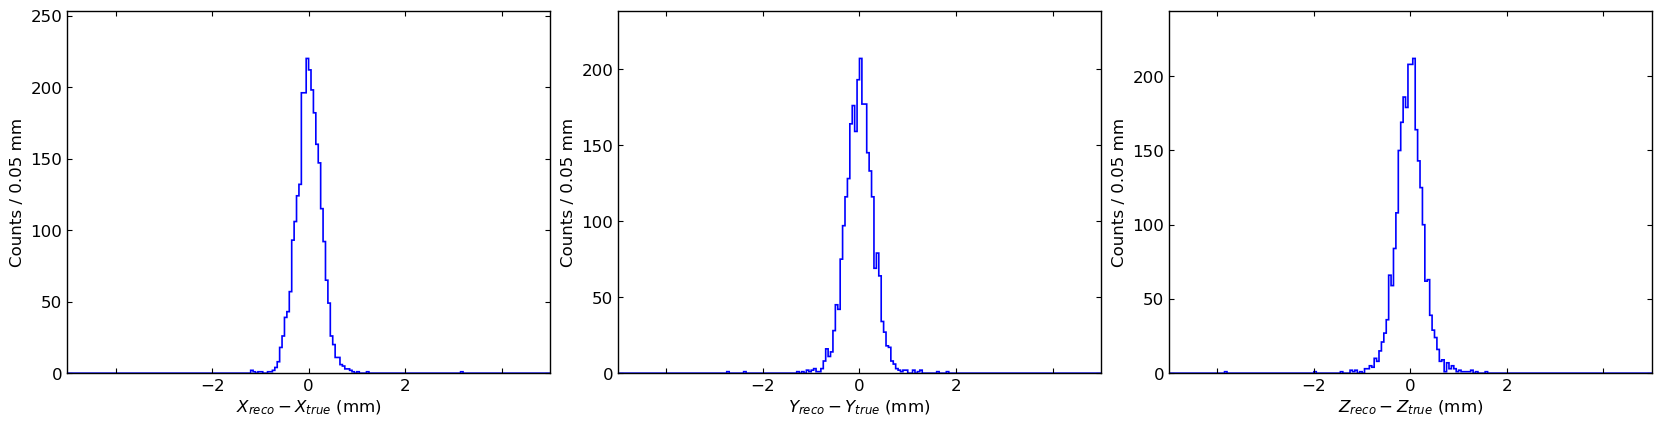

In [29]:
histograms = {}
statistics = {}
vertex_mask = result["VertexOK"] & result["TruthOK"]
# X、Y、Z 从左到右排列，每个绘图区沿用 style_axes 中的 4:3 比例。
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), layout="constrained")
for coordinate, (axis, ax) in enumerate(zip("XYZ", axes)):
    counts, edges, stats = residual_plot(result["VertexDelta"][vertex_mask, coordinate],
        rf"${axis}_{{reco}}-{axis}_{{true}}$ (mm)", "mm", f"dv{axis.lower()}", ax=ax)
    histograms[f"dv{axis.lower()}_counts"] = counts
    histograms[f"dv{axis.lower()}_edges"] = edges
    statistics[f"dv{axis.lower()}"] = stats
for ax in axes:
    finish_axes(fig, ax)
save_figure(fig, "vertex_xyz")
plt.show()


## 8. 第二步结果：反冲质子 theta 残差

重建方向由重建顶点与同组 X1、Y1 条带确定；theta 为它与 `ReactionConditions::GetBeamDirection()` 等价方向的夹角。真值取同一事件的 `fRC_Theta[0]`，两者均在同一束流参考系下以 deg 表示。


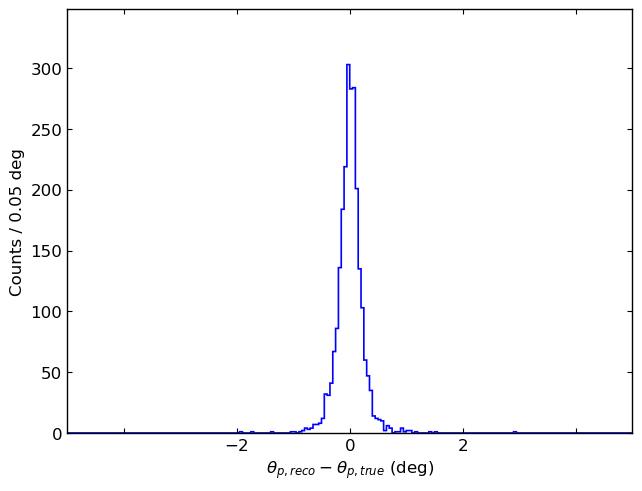

dtheta_p {'N': 2375, 'mean': 0.00958214290137724, 'std': 0.34565263722815215, 'underflow': 0, 'overflow': 0, 'outside_view': 1}


In [30]:
theta_mask = result["RecoilTrackOK"] & result["TruthOK"] & result["BeamOK"]
counts, edges, stats = residual_plot(result["ProtonThetaDiff"][theta_mask],
    r"$\theta_{p,reco}-\theta_{p,true}$ (deg)", "deg", "dtheta_p")
histograms["dtheta_p_counts"] = counts
histograms["dtheta_p_edges"] = edges
statistics["dtheta_p"] = stats


## 9. subprocess 接口与批量能损修正

运行本块才会调用命令行 ROOT 解释执行当前目录的 `KinLoss.C`，不会运行原 HitsLocal 宏。alpha 的沉积总能量为四层 SSD + 同侧 DeltaE + ClusterGAGG；质子为同组 X1/X2/Y1 SSD + 同组 GAGG。按照原宏，用重建顶点和重建方向计算圆柱 LH2 靶内剩余路程，再反演顶点总动能。

只修正 LH2 内的能损，积分步长 0.01 cm。沿用现有 ExitDistance 对前向出射的限制，不补加未建模的死层、包壳或逃逸能量。真值动能不参与能损反演。


In [31]:
def run_cpp(mode, input_path, output_path):
    root_executable = shutil.which("root")
    if root_executable is None:
        raise RuntimeError("未找到命令行 ROOT；请在 ROOT 环境中运行能损/理论曲线单元格")
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    args = ",".join((json.dumps(mode), json.dumps(str(input_path)), json.dumps(str(output_path)),
                     repr(BEAM_ENERGY_PER_U), repr(TARGET_THICKNESS), repr(TARGET_RADIUS)))
    expression = f"{HELPER}({args})"
    # 不经过 shell；-n 禁用用户 rootlogon，避免启动宏产生外部副作用；不使用 ACLiC 的 +。
    command = [root_executable, "-n", "-l", "-b", "-q", expression]
    output_path.write_text("")  # 本次输出表；避免解释错误时误读上次结果。
    completed = subprocess.run(command, cwd=WORK_DIR, capture_output=True, text=True)
    log = completed.stdout + "\n" + completed.stderr
    (OUT_DIR / f"{mode}.log").write_text(log)
    if completed.returncode != 0 or not output_path.exists():
        raise RuntimeError(f"C++ {mode} 失败，查看 {OUT_DIR / (mode + '.log')}")
    print(f"C++ {mode} 完成；日志：{OUT_DIR / (mode + '.log')}")


In [32]:
requests = []
for species, prefix, track_flag, direction_key in (
    (4, "Alpha", "VertexOK", "ClusterDirection"),
    (1, "Proton", "RecoilTrackOK", "RecoilDirection"),
):
    selected = result[track_flag] & result["TruthOK"] & (result[prefix + "DetectorE"] > 0.0)
    entries = np.flatnonzero(selected)
    rows = np.column_stack((entries, np.full(len(entries), species), result[prefix + "DetectorE"][entries],
                            result["VertexWorld"][entries], result[direction_key][entries]))
    requests.append(rows)
requests = np.concatenate(requests, axis=0)
OUT_DIR.mkdir(parents=True, exist_ok=True)
energy_input = OUT_DIR / "energy_in.txt"
energy_output = OUT_DIR / "energy_out.txt"
np.savetxt(energy_input, requests, fmt=["%d", "%d"] + ["%.17g"] * 7)

if len(requests):
    run_cpp("energy", energy_input, energy_output)
    energy_table = np.loadtxt(energy_output, ndmin=2)
    # 核对 C++ 返回的 entry/species 顺序，防止短文件或错行写回事件。
    if energy_table.shape != (len(requests), 5) or not np.array_equal(energy_table[:, :2], requests[:, :2]):
        raise ValueError("C++ 能损返回表与请求的事件/粒子未对齐")
    for row in energy_table:
        entry, species, success = (int(x) for x in row[:3])
        prefix = "Alpha" if species == 4 else "Proton"
        result[prefix + "Path"][entry] = row[3]
        if success == 1 and np.isfinite(row[4]) and row[4] > 0.0:
            result[prefix + "EnergyOK"][entry] = True
            result[prefix + "Energy"][entry] = row[4]
else:
    print("没有满足能量输入要求的事件；保留所有事件及失败标志。")
print("alpha / proton 能量成功数：", result["AlphaEnergyOK"].sum(), result["ProtonEnergyOK"].sum())


C++ energy 完成；日志：/Users/yemingxin/ROOT_Exercise/MachineLearning/ReadROOT/ReadStruct/output/20261026/181132/energy.log
alpha / proton 能量成功数： 2577 2369


## 10. 导出弹性散射理论曲线

`4He+p → p+4He`，Ex=0，采用输入配置的固定入靶束流能量（本文件为 200 MeV/u）。C++ 接口的 proton/residue 曲线原本输出 MeV/u，辅助宏分别乘以 A=1/4，统一成总动能 MeV。每条运动学分支分别保留，避免跨分支错误连线。

固定入靶能量曲线是参考：150 mm 厚靶中不同反应深度对应不同束流能量，重建散点不应被要求全部落在这条固定曲线上。


In [33]:
curve_path = OUT_DIR / "curve.txt"
run_cpp("curve", "", curve_path)
curves = np.loadtxt(curve_path, ndmin=2)
if curves.shape[1] != 4 or not {1, 4}.issubset(set(curves[:, 0].astype(int))):
    raise ValueError("理论曲线表不完整，请查看 curve.log")
print("理论曲线点数：", len(curves))


C++ curve 完成；日志：/Users/yemingxin/ROOT_Exercise/MachineLearning/ReadROOT/ReadStruct/output/20261026/181132/curve.log
理论曲线点数： 33100


## 11. 第三步结果：质子和 alpha 的 E–theta 图

一行两列，左侧为质子，右侧为 alpha；各绘图区等大且为 4:3，各自保留对数计数色标，合并保存为 `etheta_pa.pdf/png`。

横轴是重建出射方向相对于已指定束流方向的实验室角，纵轴是能损修正后的顶点总动能。二维统计只接受对应能量、径迹和束流方向有效的事件，不要求另一个粒子也有有效能量；两图各自打印有效样本数与显示范围外计数。


In [34]:
def energy_angle_plot(prefix, species, x_edges, y_edges, stem, ax=None):
    mask = result[prefix + "EnergyOK"] & result["BeamOK"]
    theta = result[prefix + "Theta"][mask]
    energy = result[prefix + "Energy"][mask]
    histogram, x_edges, y_edges = np.histogram2d(theta, energy, bins=(x_edges, y_edges))
    single_panel = ax is None
    if single_panel:
        fig, ax = plt.subplots(figsize=(6.7, 4.8), layout="constrained")
    else:
        fig = ax.figure
    shown = np.ma.masked_less_equal(histogram.T, 0.0)
    mesh = ax.pcolormesh(x_edges, y_edges, shown, shading="flat", cmap="turbo",
                         norm=LogNorm(vmin=1.0, vmax=max(2.0, float(histogram.max(initial=0.0)))))
    fig.colorbar(mesh, ax=ax, pad=0.0, fraction=0.05)
    theory = curves[curves[:, 0] == species]
    for branch in np.unique(theory[:, 1]):
        points = theory[theory[:, 1] == branch]
        ax.plot(points[:, 2], points[:, 3], color="black", linewidth=1.0,
                linestyle="-" if branch == 0 else "--", alpha=0.8)
    ax.set_xlim(x_edges[0], x_edges[-1])
    ax.set_ylim(y_edges[0], y_edges[-1])
    particle = "p" if species == 1 else r"\alpha"
    ax.set_xlabel(rf"$\theta_{{{particle}}}^{{lab}}$ (deg)", loc="center")
    ax.set_ylabel(rf"$E_{{{particle}}}^{{vertex}}$ (MeV)", loc="center")
    style_axes(ax)
    finish_axes(fig, ax)
    if single_panel:
        save_figure(fig, stem)
        plt.show()
    histograms[stem + "_counts"] = histogram
    histograms[stem + "_xedges"] = x_edges
    histograms[stem + "_yedges"] = y_edges
    outside = np.sum((theta < x_edges[0]) | (theta > x_edges[-1]) |
                     (energy < y_edges[0]) | (energy > y_edges[-1]))
    statistics[stem] = {"N": int(mask.sum()), "outside_view": int(outside)}
    print(stem, statistics[stem])
    if not histogram.any():
        print("当前显示范围内无二维计数；图中仍保留理论曲线。")


etheta_p {'N': 2369, 'outside_view': 0}
etheta_a {'N': 2577, 'outside_view': 0}


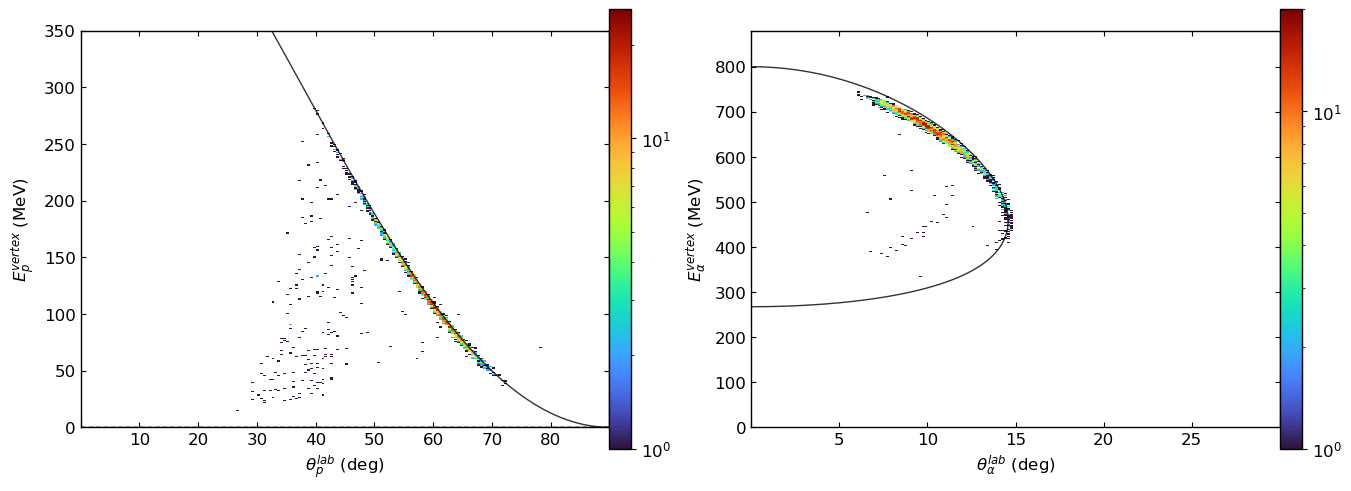

In [35]:
# 集中设置分箱和显示范围；只影响图，不改变事件切选或能量计算。
PROTON_THETA_EDGES = np.linspace(0.0, 90.0, 181)
PROTON_ENERGY_EDGES = np.linspace(0.0, 350.0, 351)
ALPHA_THETA_EDGES = np.linspace(0.0, 30.0, 181)
ALPHA_ENERGY_EDGES = np.linspace(0.0, BEAM_ENERGY_PER_U * 4.0 * 1.1, 401)
# 一行两列：左质子、右 alpha；各自保留独立色标和原有坐标范围。
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.8), layout="constrained")
energy_angle_plot("Proton", 1, PROTON_THETA_EDGES, PROTON_ENERGY_EDGES, "etheta_p", ax=axes[0])
energy_angle_plot("Alpha", 4, ALPHA_THETA_EDGES, ALPHA_ENERGY_EDGES, "etheta_a", ax=axes[1])
for ax in axes:
    finish_axes(fig, ax)
save_figure(fig, "etheta_pa")
plt.show()


## 12. 保存逐事件结果、直方图与计算来源

`recons.npz` 保留全部事件、成功标志、重建/真值和能量；`recons.root` 的 `ReconstructionTree` 保留相同记录，向量拆分为 X/Y/Z 标量，便于后续与 `.C` 逐 entry 对照。原 ROOT 文件不修改、不克隆。

图片为 `vertex_xyz/dtheta_p/etheta_pa` 的 PDF 和 PNG。输出放在 `output/YYYYMMDD/HHMMSS`。当前 Notebook 没有执行，不能据代码相同就声称分布或数值已经与原宏一致。


In [36]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
np.savez_compressed(OUT_DIR / "recons.npz", **result)
np.savez_compressed(OUT_DIR / "hist.npz", **histograms)
columns = {}
for key, values in result.items():
    if values.ndim == 1:
        columns[key] = values
    else:
        for axis, letter in enumerate("XYZ"):
            columns[key + letter] = values[:, axis]
with uproot.recreate(OUT_DIR / "recons.root") as output_file:
    # 明确写成 TTree，便于 ROOT/C++ 直接读取。
    output_file.mktree("ReconstructionTree", {key: values.dtype for key, values in columns.items()})
    output_file["ReconstructionTree"].extend(columns)
provenance = {
    "input": str(INPUT), "input_size": INPUT.stat().st_size, "input_mtime_ns": INPUT.stat().st_mtime_ns,
    "entries": int(n_entries), "source_macro": str(REFERENCE_MACRO),
    "beam_direction": "ReactionConditions truth; input has no VirtualBDC",
    "geometry": "DetectorConfiguration embedded in input ROOT",
    "energy_units": "total kinetic energy MeV", "position_units": "mm", "angle_units": "deg",
    "beam_energy_per_u": BEAM_ENERGY_PER_U, "target_thickness_mm": TARGET_THICKNESS,
    "target_radius_mm": TARGET_RADIUS, "statistics": statistics,
}
(OUT_DIR / "run.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2))
(OUT_DIR / "detector.txt").write_text(detector_text)
(OUT_DIR / "reaction.txt").write_text(reaction_text)
print("结果已保存：", OUT_DIR)
print("逐事件输出数：", len(result["Entry"]))


结果已保存： /Users/yemingxin/ROOT_Exercise/MachineLearning/ReadROOT/ReadStruct/output/20261026/181132
逐事件输出数： 300000
